Training Samples: 25000
Testing Samples: 25000
Training Data Shape: (25000, 200)
Testing Data Shape: (25000, 200)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 94ms/step - accuracy: 0.5676 - loss: 0.6646 - val_accuracy: 0.7968 - val_loss: 0.5159
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.6615 - loss: 0.5729 - val_accuracy: 0.8330 - val_loss: 0.5106
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 93ms/step - accuracy: 0.7351 - loss: 0.5254 - val_accuracy: 0.8030 - val_loss: 0.5035
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 91ms/step - accuracy: 0.7515 - loss: 0.4783 - val_accuracy: 0.6500 - val_loss: 0.5890
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.8487 - loss: 0.3394 - val_accuracy: 0.8652 - val_loss: 0.3467
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8542 - loss: 0.3713
Test Loss: 0.37128403782844543
Test Accuracy: 0.8541600108146667


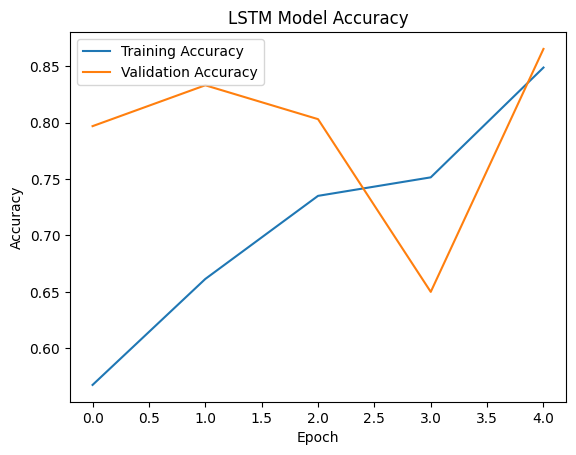

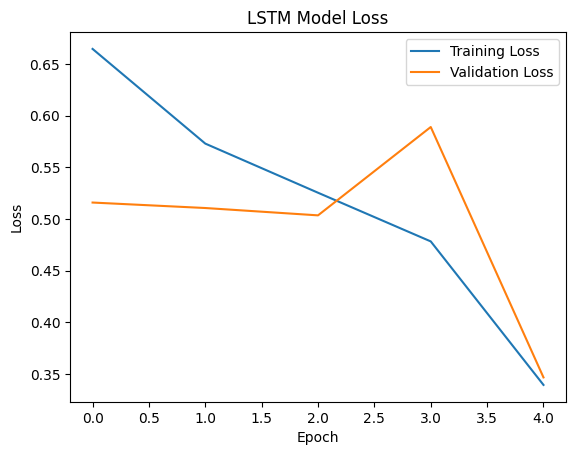


Positive Review:
Sentiment: Positive
Prediction Score: 0.8391423225402832

Negative Review:
Sentiment: Negative
Prediction Score: 0.25302207469940186

Result: LSTM-based sentiment analysis completed.


In [2]:
# Experiment No. 8
# Sentiment Analysis using RNN with LSTM

# 1. Import required libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt

# 2. Set parameters
vocab_size = 10000
max_length = 200

# 3. Load the IMDB dataset
(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.imdb.load_data(num_words=vocab_size)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

# 4. Pad sequences to equal length
x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post'
)

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# 5. Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 6. Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 7. Display model architecture
model.summary()

# 8. Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# 9. Evaluate the model
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 10. Plot training and validation accuracy
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('LSTM Model Accuracy')
plt.legend()
plt.show()

# 11. Plot training and validation loss
plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LSTM Model Loss')
plt.legend()
plt.show()

# 12. Test with a new movie review
word_index = tf.keras.datasets.imdb.get_word_index()

def predict_sentiment(review):
    # Convert review words into IMDB word indexes
    words = review.lower().split()
    sequence = []

    for word in words:
        index = word_index.get(word)

        if index is not None and index < vocab_size - 3:
            sequence.append(index + 3)
        else:
            sequence.append(2)  # Unknown word

    padded = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post'
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: Positive")
    else:
        print("Sentiment: Negative")

    print("Prediction Score:", float(prediction))

# 13. Test example reviews
print("\nPositive Review:")
predict_sentiment(
    "This movie was excellent and I really enjoyed it"
)

print("\nNegative Review:")
predict_sentiment(
    "This movie was boring and terrible"
)

# 14. Result
print("\nResult: LSTM-based sentiment analysis completed.")